# 1. Quick start: simulate, infer, reconstruct

This notebook shows the basic workflow of `gwbf_foregrounds`:

1. choose a model,
2. simulate a mock LISA dataset,
3. get the SBI posterior of the string tension Gμ, the LISA noise and the foreground amplitudes,
4. reconstruct the spectrum of every component.

The trained network is downloaded automatically the first time (~230 MB).

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from gwbf_foregrounds import FULL, GBEXB, NOFG, data, posterior, reconstruct, stats
from gwbf_foregrounds.plotting.spectra import plot_reconstruction

## Models

Three models, each with its own trained network:

In [2]:
for m in (FULL, GBEXB, NOFG):
    print(f"{m.name:6s} {m.ndim} parameters: {', '.join(m.param_names)}")
    print(f"       {m.description}")

full   7 parameters: logGmu, A_p, A_acc, logA_Gal, logA_ExB, logA_ExWB, logA_EMRI
       Strings + WDs, SOBHBs, ExWDs, EMRIs (inferred) + MBHBs (fixed); HS, BOS
gbexb  5 parameters: logGmu, A_p, A_acc, logA_Gal, logA_ExB
       Strings + WDs and SOBHBs only; BOS
nofg   3 parameters: logGmu, A_p, A_acc
       Strings + instrument noise, no foregrounds; BOS


Each model knows its priors and its fiducial (injected) parameter values:

In [3]:
FULL.prior

{'logGmu': ('uniform', -18.0, -9.0),
 'A_p': ('uniform', 12.0, 18.0),
 'A_acc': ('uniform', 2.4000000000000004, 3.5999999999999996),
 'logA_Gal': ('gaussian', -7.84, 0.21),
 'logA_ExB': ('gaussian', -12.38, 0.344),
 'logA_ExWB': ('gaussian', -11.0554, 0.17),
 'logA_EMRI': ('gaussian', 0.0, 0.5)}

In [4]:
FULL.fiducial(logGmu=-13)          # sign=-1 / +1 gives the foregrounds at fiducial -1 / +1 sigma

{'A_p': 15.0,
 'A_acc': 3.0,
 'logA_Gal': -7.84,
 'logA_ExB': -12.38,
 'logA_ExWB': -11.0554,
 'logA_EMRI': 0.0,
 'logA_MBHB': 0.0,
 'logGmu': -13.0}

## Simulate a mock dataset

`simulate` returns the coarse-grained AA, EE and TT spectra (1970 frequencies each).

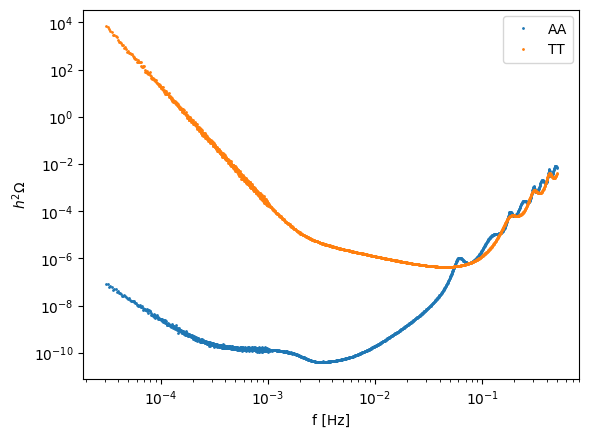

In [5]:
ds = data.simulate("full", logGmu=-13, seed=0)

plt.loglog(ds.f_Hz, ds.D_AA, ".", ms=2, label="AA")
plt.loglog(ds.f_Hz, ds.D_TT, ".", ms=2, label="TT")
plt.xlabel("f [Hz]"); plt.ylabel(r"$h^2\Omega$"); plt.legend();

Datasets can be saved and loaded again, e.g. to analyse the same data with SBI and MCMC:

In [6]:
ds.save("my_dataset.npz")
ds2 = data.Dataset.load("my_dataset.npz")
print(ds2.model, ds2.seed, ds2.params["logGmu"])

full 0 -13.0


## Posterior samples

`load_posterior("full")` downloads the trained network (or pass a path to a local `.pkl`).
Sampling 10 000 points takes a few seconds.

In [7]:
post = posterior.load_posterior("full")
samples = posterior.sample(post, ds, n=10_000, seed=0)       # (10000, 7), in FULL.param_names order
samples.shape

(10000, 7)

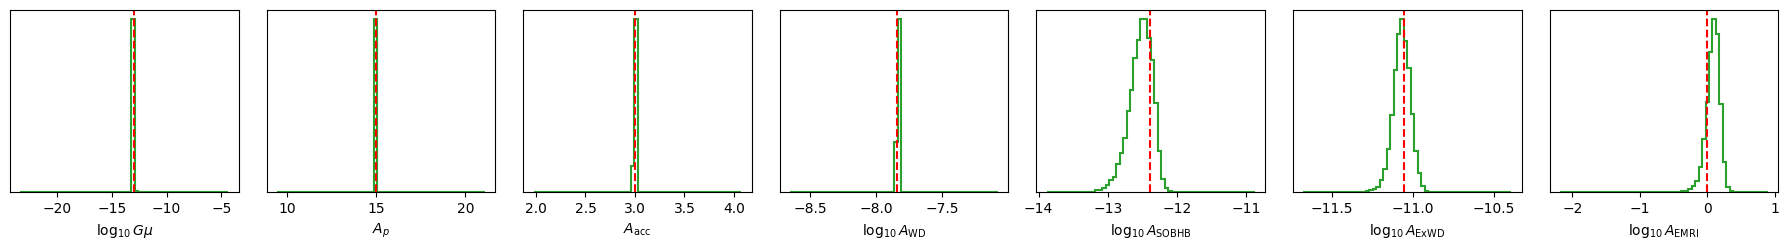

In [8]:
fig, axes = plt.subplots(1, FULL.ndim, figsize=(18, 2.6))
for ax, name, s, t in zip(axes, FULL.param_names, samples.T, FULL.theta(ds.params)):
    ax.hist(s, bins=60, histtype="step", color="C2", lw=1.5)
    ax.axvline(t, color="red", ls="--")
    ax.set_xlabel(FULL.labels([name])[0]); ax.set_yticks([])
fig.tight_layout()

## Precision on Gμ

The paper's precision: width of the 95% HDI in Gμ, in % of the injected Gμ.

In [9]:
prec, lo, hi = stats.precision_from_samples(samples[:, 0], logGmu_inj=-13)
print(f"95% HDI of log10 Gmu: [{lo:.3f}, {hi:.3f}]   ->   precision = {prec:.1f} %")

95% HDI of log10 Gmu: [-13.160, -12.942]   ->   precision = 44.9 %


## Reconstruct every spectral component

Each posterior sample gives one spectrum per component; the plot shows median, 95% band and the injected spectra (dashed).

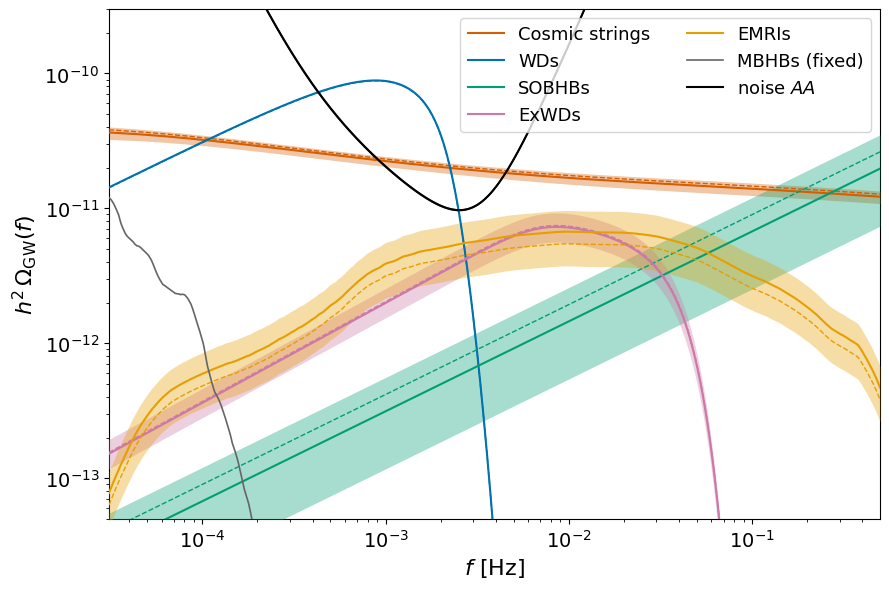

In [10]:
rec = reconstruct.reconstruct(samples, "full", ds.f_obs, truth=ds.params, max_samples=1000)
plot_reconstruction(rec, show_noise=True, ylim=(5e-14, 3e-10));

In [11]:
b = rec.bands()                      # the numbers behind the plot
b["string"]["median"][:5], b["string"][0.95][0][:5]

(array([3.64518081e-11, 3.63841336e-11, 3.62992857e-11, 3.62171599e-11,
        3.61375927e-11]),
 array([3.23424971e-11, 3.23109975e-11, 3.22603587e-11, 3.22113075e-11,
        3.21637496e-11]))

## Other models

The same code works for the other two models, e.g. strings with only WD and SOBHB foregrounds:

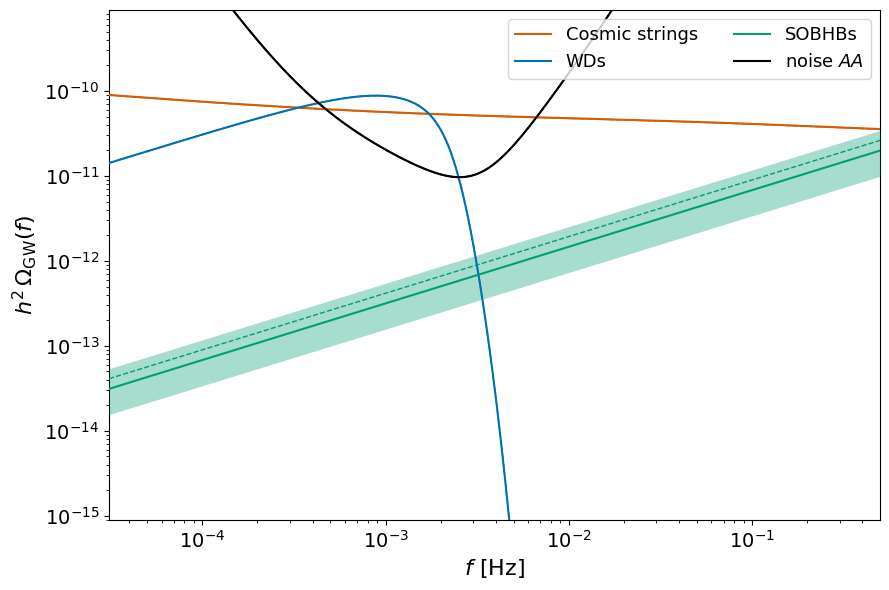

In [12]:
ds_g = data.simulate("gbexb", logGmu=-12, seed=0)
post_g = posterior.load_posterior("gbexb")
s_g = posterior.sample(post_g, ds_g, n=5000, seed=0)
rec_g = reconstruct.reconstruct(s_g, "gbexb", ds_g.f_obs, truth=ds_g.params, max_samples=500)
plot_reconstruction(rec_g, show_noise=True);

In [13]:
import os; os.remove("my_dataset.npz")